In [2]:
import pandas as pd
import numpy as np

In [ ]:
decomp_xgb = pd.read_parquet('results/sepsis_xgb_median.parquet')

In [ ]:
decomp_xgb.columns = [round(c, ndigits=2) for c in decomp_xgb.columns[:-2]]

In [ ]:
decomp_xgb = decomp_xgb.dropna()
std_diff = decomp_xgb.diff(axis=1).iloc[:, 1:].std(axis=1)
decomp_xgb['std_diff'] = std_diff

In [ ]:
arr = decomp_xgb.to_numpy()
delta2 = arr[:, 2:] - 2 * arr[:, 1:-1] + arr[:, :-2]
result = np.sum(delta2**2, axis=1)
decomp_xgb['second_derivative'] = result
decomp_xgb.to_parquet('smooth_example.parquet')

PLOT

In [3]:
label_df = pd.read_parquet('data/decomp_test.parquet')

In [4]:
df = pd.read_parquet('smooth_example.parquet', columns=['std_diff', 'second_derivative'])

In [5]:
df = pd.merge(df, label_df, right_on='CSN', left_index=True)
df = df.drop(columns=['Criteria_from_room'])

In [6]:
neg_df = df[df['Label']==False]
neg_df = neg_df.drop(columns=['Criteria_from_arrive', 'Label'])

In [7]:
pos_df = df[df['Label']==True]
pos_df = pos_df.drop(columns=['Label', 'CSN'])

In [8]:
pos_df_1 = pos_df[(pos_df['Criteria_from_arrive'] < 2) & (pos_df['Criteria_from_arrive'] >= 1)]
pos_df_2 = pos_df[(pos_df['Criteria_from_arrive'] < 3) & (pos_df['Criteria_from_arrive'] >= 2)]
pos_df_3 = pos_df[(pos_df['Criteria_from_arrive'] < 4) & (pos_df['Criteria_from_arrive'] >= 3)]
pos_df_4 = pos_df[(pos_df['Criteria_from_arrive'] < 5) & (pos_df['Criteria_from_arrive'] >= 4)]
pos_df_5 = pos_df[(pos_df['Criteria_from_arrive'] < 6) & (pos_df['Criteria_from_arrive'] >= 5)]
pos_df_6 = pos_df[(pos_df['Criteria_from_arrive'] < 7) & (pos_df['Criteria_from_arrive'] >= 6)]
pos_df_7 = pos_df[(pos_df['Criteria_from_arrive'] < 8) & (pos_df['Criteria_from_arrive'] >= 7)]
pos_df_8 = pos_df[(pos_df['Criteria_from_arrive'] < 9) & (pos_df['Criteria_from_arrive'] >= 8)]
pos_df_9 = pos_df[(pos_df['Criteria_from_arrive'] >= 9)]

In [9]:
dfs = [pos_df_1, pos_df_2, pos_df_3, pos_df_4, pos_df_5, pos_df_6, pos_df_7, pos_df_8, pos_df_9, neg_df]

In [18]:
labels = [1, 2, 3, 4, 5, 6, 7, 8, 9, 'neg']
columns = ['std_diff', 'second_derivative']

In [12]:
import matplotlib.pyplot as plt

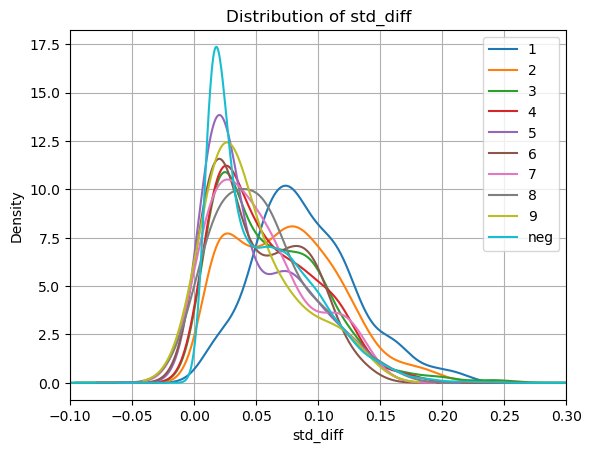

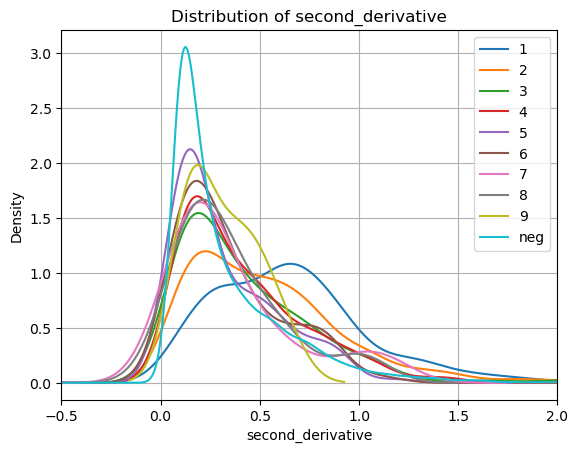

In [19]:
# Plot KDEs
for col in columns:
    plt.figure()
    for df, label in zip(dfs, labels):
        df[col].plot(kind='kde', label=label)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.legend()
    plt.grid(True)
    if col == 'std_diff':
        plt.xlim(-0.1, 0.3)
    elif col == 'second_derivative':
        plt.xlim(-0.5, 2.0)
    plt.show()

SECOND ORDER DERIVATIVE / STD

In [ ]:
decomp_xgb = pd.read_parquet('results/decomp_xgb.parquet')
decomp_xgb.columns = [round(c, ndigits=2) for c in decomp_xgb.columns[:-2]]

In [ ]:
decomp_xgb = decomp_xgb.dropna()
std_diff = decomp_xgb.diff(axis=1).iloc[:, 1:].std(axis=1)
decomp_xgb['std_diff'] = std_diff

In [ ]:
arr = decomp_xgb.to_numpy()
delta2 = arr[:, 2:] - 2 * arr[:, 1:-1] + arr[:, :-2]
result = np.sum(delta2**2, axis=1)
decomp_xgb['second_derivative'] = result